# 01 — Dataset audit and leakage-safe splits

**Project 11 — Wildlife Species Identification and Conflict Alert System** · Phase I evidence.

This notebook is the dataset audit the Phase I rubric marks: *source, licence, balance, preprocessing, split strategy, leakage checks and risks*. Every number below is computed from the label files, not quoted from a dataset README. Nothing here needs the images or a GPU — it runs on the 203k-row metadata table in seconds, which is why it was done before any training.

Source: `thanhquang71/iwildcam-v2-0-2020-wilds-dataset` (iWildCam v2.0, the WILDS camera-trap benchmark built from the Oxford WildCam / Snapshot Safari network). Log entry: `docs/SOURCE_LOG.md`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "DL_PBL"
META_CSV = ROOT / "data/raw/iwildcam_meta/iwildcam_v2.0/metadata.csv"
CATS_CSV = ROOT / "data/raw/iwildcam_meta/iwildcam_v2.0/categories.csv"
SPLITS = ROOT / "data/splits"
IMG_DIR = ROOT / "data/raw/iwildcam_v2.0/train"
SEED = 13
print("root     :", ROOT)
print("metadata :", META_CSV.exists(), "| categories:", CATS_CSV.exists(), "| splits:", SPLITS.exists())

root     : C:\Users\xxshi\Desktop\PYTHOM\DL_PBL
metadata : True | categories: True | splits: True


In [2]:
meta = pd.read_csv(META_CSV, index_col=0, parse_dates=["datetime"])
cats = pd.read_csv(CATS_CSV)
meta["class_name"] = meta.category_id.map(dict(zip(cats.category_id, cats.name)))
meta["date"] = meta.datetime.dt.strftime("%Y-%m-%d")
meta["hour"] = meta.datetime.dt.hour
meta[["split", "location", "seq_id", "y", "category_id", "class_name", "datetime", "filename"]].head(4)

,split,location,seq_id,y,category_id,class_name,datetime,filename
0,id_test,3,300484b8-7d42-11eb-8fb5-0242ac1c0002,1,2,tayassu pecari,2013-06-01 06:55:00,97f407ac-21bc-11ea-a13a-137349068a90.jpg
1,id_test,3,300484b8-7d42-11eb-8fb5-0242ac1c0002,1,2,tayassu pecari,2013-06-01 06:55:01,954d7740-21bc-11ea-a13a-137349068a90.jpg
2,id_test,3,300484b8-7d42-11eb-8fb5-0242ac1c0002,1,2,tayassu pecari,2013-06-01 06:55:02,86b3a4fc-21bc-11ea-a13a-137349068a90.jpg
3,id_test,3,300484b8-7d42-11eb-8fb5-0242ac1c0002,1,2,tayassu pecari,2013-06-01 06:55:03,90a74fea-21bc-11ea-a13a-137349068a90.jpg


## 1. Corpus shape

One row per image. The three columns that matter for the rest of the project: `seq_id` (a single animal visit, i.e. one burst of frames), `location` (a camera site) and `datetime`. Species classification, the LSTM movement model and the conflict-alert rule are all built on those.

In [3]:
seq_sizes = meta.groupby("seq_id").size()
day_sizes = meta.groupby(["location", "date"]).size()
print(f"images             : {len(meta):,}")
print(f"camera sites       : {meta.location.nunique()}")
print(f"sequences (visits) : {meta.seq_id.nunique():,}")
print(f"species present    : {meta.category_id.nunique()} of {len(cats)} taxonomy entries")
print(f"date range         : {meta.datetime.min()} -> {meta.datetime.max()}")
print(f"empty frames       : {(meta.y == 0).mean():.1%}  (label 0 = empty)")
print(f"frames per visit   : median {seq_sizes.median():.0f} / p90 {seq_sizes.quantile(0.9):.0f} / max {seq_sizes.max()}")
print(f"camera-day groups  : {len(day_sizes):,} | median {day_sizes.median():.0f} / p95 {day_sizes.quantile(0.95):.0f} / max {day_sizes.max():,}")

images             : 203,029
camera sites       : 323
sequences (visits) : 36,484
species present    : 182 of 206 taxonomy entries
date range         : 2013-01-01 18:26:53 -> 2015-11-12 04:49:18
empty frames       : 34.2%  (label 0 = empty)
frames per visit   : median 5 / p90 10 / max 10
camera-day groups  : 7,538 | median 10 / p95 90 / max 3,476


Two facts drive the whole design:

* **A third of the corpus contains no animal.** Accuracy alone is therefore meaningless (a model that always predicts `empty` scores ~34%), and *false alerts per camera-day* is a genuine, countable failure mode rather than a hypothetical one.
* **Frames come in bursts** (median 5, max 10 per visit). Any split that puts two frames of the same visit on opposite sides leaks, because those frames are near-duplicates. This is the most common way a camera-trap project overstates its own result.

class_name
empty                       69487
meleagris ocellata          16282
crax rubra                  12408
aepyceros melampus           8440
cephalophus nigrifrons       7414
tayassu pecari               5770
dasyprocta punctata          5753
leopardus pardalis           5611
urocyon cinereoargenteus     4422
bos taurus                   4353

classes with <100 images : 110   |   <10 images : 51
most common class vs median class : 1654x


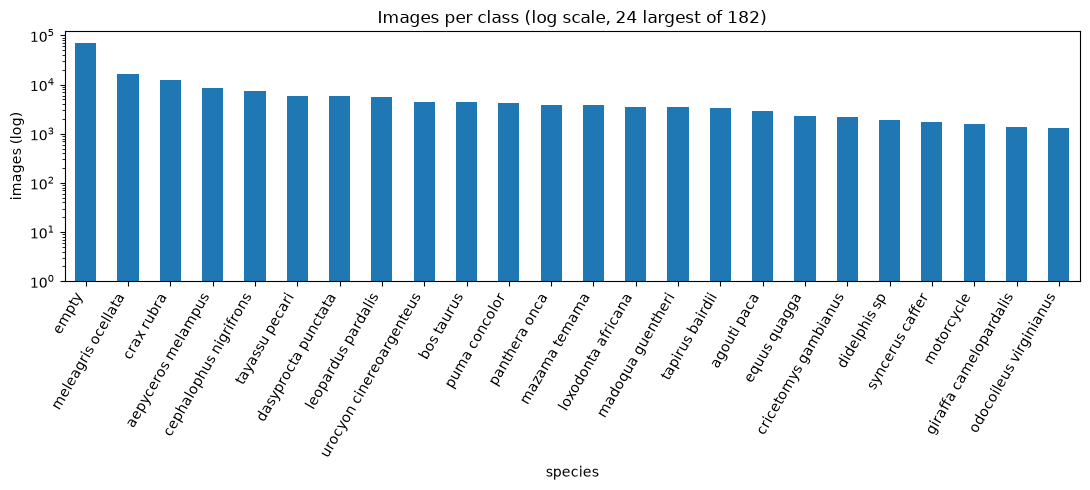

In [4]:
counts = meta.groupby("class_name").size().sort_values(ascending=False)
top = counts.head(24)
ax = top.plot.bar(figsize=(11, 5), log=True, title="Images per class (log scale, 24 largest of 182)")
ax.set_xlabel("species")
ax.set_ylabel("images (log)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
print(counts.head(10).to_string())
print()
print(f"classes with <100 images : {(counts < 100).sum()}   |   <10 images : {(counts < 10).sum()}")
print(f"most common class vs median class : {counts.max() / counts.median():.0f}x")

Extreme imbalance is why the rubric's headline number for this project is **macro F1** rather than accuracy: with 110 categories under 100 images, accuracy can rise while a rare species is never recognised. The taxonomy is cut to the 12 most-populated species plus `empty` for the Phase I window; the dropped species are a documented limitation, not a silent one.

In [5]:
per_split = meta.groupby("split").agg(images=("image_id", "size"), sites=("location", "nunique"),
                                      sequences=("seq_id", "nunique"), classes=("category_id", "nunique"))
per_split.to_string()

'         images  sites  sequences  classes\nsplit                                     \nid_test    8154    164       1474       87\nid_val     7314    146       1352       71\ntest      42791     48       7016      102\ntrain    129809    243      24109      182\nval       14961     32       2533       75'

## 2. Splits used, and one wrong inference corrected

The label table carries five official splits (`train`, `val`, `id_val`, `id_test`, `test`) and they are
cleanly disjoint: `train`/`val`/`test` share no camera site and no sequence, and the v2.0 release notes
state they do not overlap on date either. That is a stronger split than anything we could invent, so the
official `train`/`val`/`test` are used, cut to 12 species plus `empty` and capped by whole sequence.

Correction recorded because it matters: an earlier pass of this notebook concluded that image files
existed only for the official `train` split, because `iwildcam_v2.0/val/<uuid>.jpg` returns 404 from the
Kaggle API. After the 12 GB corpus was downloaded and extracted, filename matching shows every split's
images present - all five splits store them in one folder named `train`, keyed by uuid. A 404 on a
guessed path is not evidence of absence. The recarved holdouts (`--splits recarved`) are kept as a
robustness check.

In [6]:
manifest = json.loads((SPLITS / "manifest.json").read_text(encoding="utf-8"))
print("generated    :", manifest["generated_utc"])
print("seed         :", manifest["seed"], "| species kept:", manifest["top_k_species"], "+ empty")
print("split sizes  :", manifest["split_sizes"])
print("camera sites :", manifest["split_locations"])
print("sequences    :", manifest["split_sequences"])
print("val days     :", manifest["val_camera_days"], "| held-out test sites:", manifest["held_out_test_sites"])
print("coverage     :", json.dumps(manifest["species_coverage"], indent=2))
pd.DataFrame(manifest["leakage_checks"]).T

generated    : 2026-10-23T16:30:54.032411+00:00
seed         : 13 | species kept: 12 + empty
split sizes  : {'train': 36060, 'val': 10234, 'test': 19928}
camera sites : {'train': 199, 'val': 32, 'test': 44}
sequences    : {'train': 5543, 'val': 1843, 'test': 2952}
val days     : n/a (official split) | held-out test sites: n/a (official split sites)
coverage     : {
  "train_classes": 13,
  "test_classes": 13,
  "classes_absent_from_test": [],
  "test_classes_under_100_images": [
    "tayassu pecari"
  ]
}


,seq,camera_day,location
train_vs_val,0,0,0
train_vs_test,0,0,0
val_vs_test,0,0,0
duplicate_filenames,0,0,0


Read that table as the leakage proof:

* `seq == 0` on every pair - no animal visit is split across train/val/test.
* `camera_day == 0` on every pair - no camera site/day session is shared.
* `location == 0` on every pair - `test` is made of camera sites absent from `train` and `val`, so a
  score on it is an out-of-distribution claim, not a same-camera claim. This is the WILDS benchmark's
  own guarantee, inherited rather than re-derived.
* `duplicate_filenames == 0` - no image appears twice.

Class capping is per class **by whole sequence**, never by frame, so trimming a class cannot leave a
burst half in and half out.

In [7]:
frames = {s: pd.read_csv(SPLITS / f"{s}.csv") for s in ("train", "val", "test")}
cm = pd.read_csv(SPLITS / "class_map.csv").set_index("label")["class_name"]
table = cm.to_frame("class_name")
for s, df in frames.items():
    table[s] = df.groupby("label").size()
for s in ("train", "val", "test"):
    table[s] = table[s].fillna(0).astype(int)
table

,class_name,train,val,test
label,,,,
0,empty,2999,2399,2996
1,tayassu pecari,2991,1430,2
2,dasyprocta punctata,2997,210,1087
3,puma concolor,2991,241,776
4,leopardus pardalis,2996,470,1126
5,panthera onca,1966,496,1240
6,bos taurus,1751,276,1986
7,aepyceros melampus,2642,267,2991
8,cephalophus nigrifrons,2996,931,1420


In [8]:
print("empty share per split:", {s: round(float((df.label == 0).mean()), 3) for s, df in frames.items()})
print("images per split     :", {s: len(df) for s, df in frames.items()})
print("species per split    :", {s: int(df[df.label > 0].label.nunique()) for s, df in frames.items()})
print()
print("Class balance is enforced on train only; val and test keep whatever the held-out days and")
print("sites contain, which is why the test set is missing a species that train has (see table above).")

empty share per split: {'train': 0.083, 'val': 0.234, 'test': 0.15}
images per split     : {'train': 36060, 'val': 10234, 'test': 19928}
species per split    : {'train': 12, 'val': 12, 'test': 12}

Class balance is enforced on train only; val and test keep whatever the held-out days and
sites contain, which is why the test set is missing a species that train has (see table above).


## 3. Measured properties the report has to state

Verified against real files rather than the dataset's own claims.

In [9]:
imgs = sorted(IMG_DIR.glob("*.jpg"))
if imgs:
    sizes = [Image.open(p).size for p in imgs[:120]]
    hs = sorted(h for _, h in sizes)
    ws = sorted(w for w, _ in sizes)
    print(f"sampled {len(sizes)} local images")
    print(f"height : min {hs[0]} / median {hs[len(hs) // 2]} / max {hs[-1]}")
    print(f"width  : min {ws[0]} / median {ws[len(ws) // 2]} / max {ws[-1]}")
else:
    print("no local images yet - run src/vision/fetch_images.py")
print()
print("The annotation JSON declares 1920x1080 while RELEASE_v2.0.txt declares height 448.")
print("The measurement above settles it; quote the measurement, not either file.")

sampled 120 local images
height : min 448 / median 448 / max 448
width  : min 560 / median 597 / max 796

The annotation JSON declares 1920x1080 while RELEASE_v2.0.txt declares height 448.
The measurement above settles it; quote the measurement, not either file.


animal frames recorded between 18:00 and 06:00: 32.1%
A large night component means infrared frames are a realistic robustness / out-of-distribution
axis for the error analysis, and a reason to report per-site rather than overall accuracy.


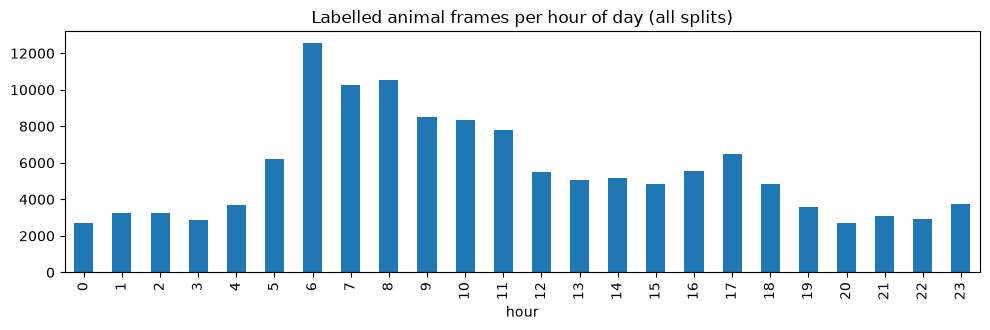

In [10]:
daylight = meta.loc[meta.y != 0, "hour"]
ax = daylight.value_counts().sort_index().reindex(range(24), fill_value=0).plot(
    kind="bar", figsize=(10, 3.4), title="Labelled animal frames per hour of day (all splits)")
ax.set_xlabel("hour")
plt.tight_layout()
night_hours = list(range(0, 6)) + list(range(18, 24))
print(f"animal frames recorded between 18:00 and 06:00: {daylight.isin(night_hours).mean():.1%}")
print("A large night component means infrared frames are a realistic robustness / out-of-distribution")
print("axis for the error analysis, and a reason to report per-site rather than overall accuracy.")

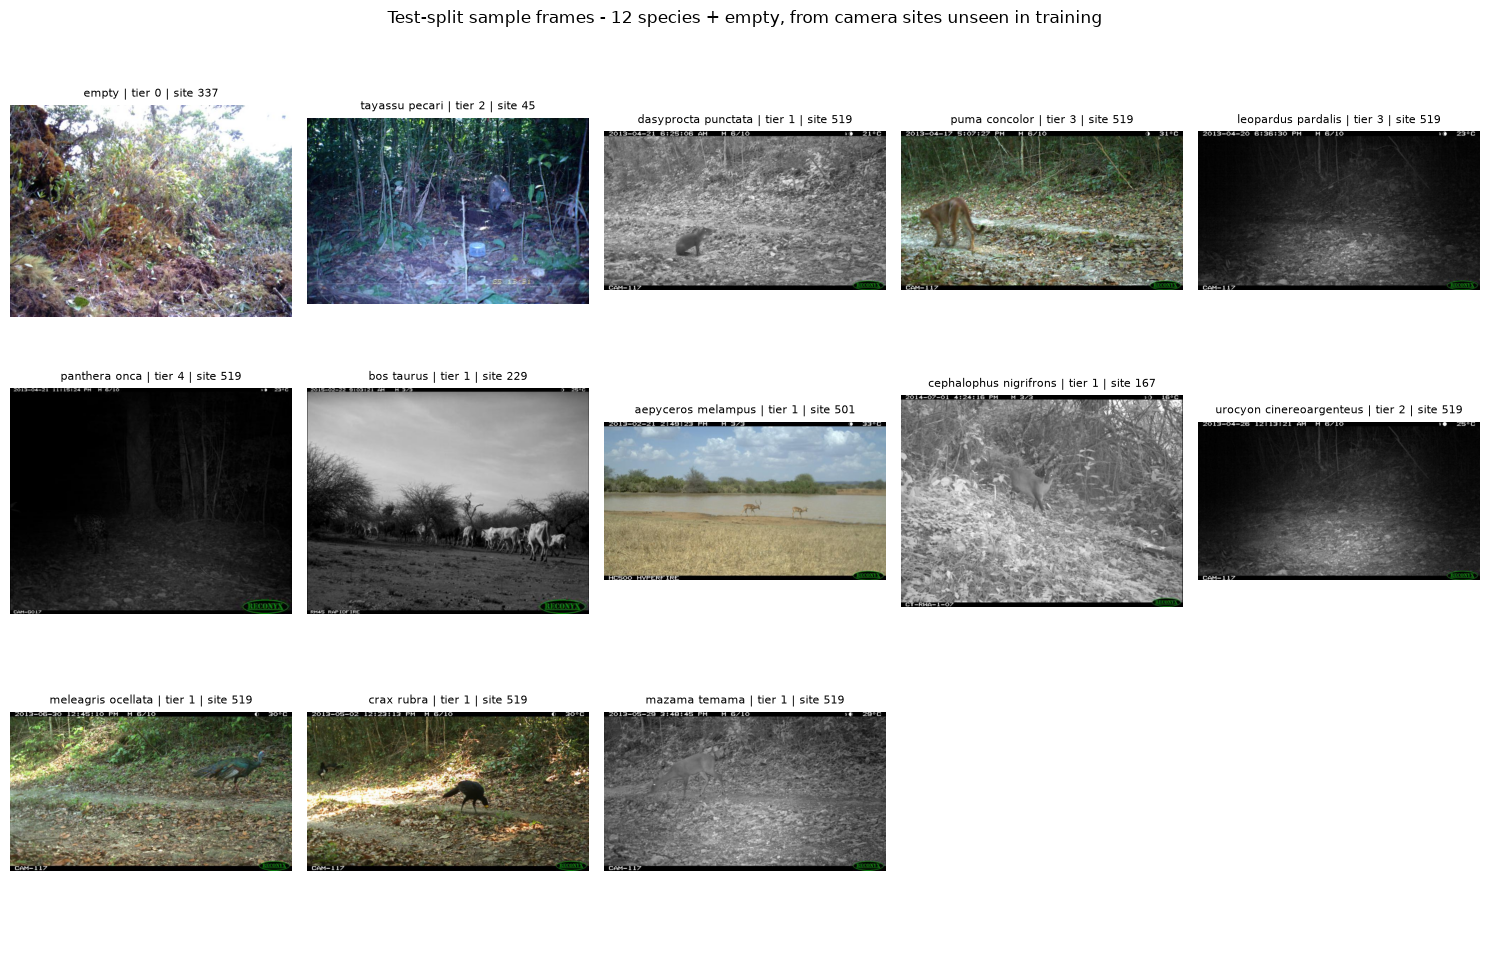

These are the images the 0.6403 macro F1 was measured on: 19,928 of them across 44 unseen sites.


In [11]:
# A real look at the data: one representative frame per class from the held-out TEST split.
# Selection is deterministic: the middle frame of each class's longest test sequence.
import sys
sys.path.insert(0, str(ROOT / "src/sequence"))
from alert import DANGER_TIER, DEFAULT_TIER

rows = []
for lab, g in frames["test"].groupby("label"):
    seq = g.groupby("seq_id").size().idxmax()
    gg = g[g.seq_id == seq].sort_values("datetime")
    rows.append(gg.iloc[len(gg) // 2])

fig, axes = plt.subplots(3, 5, figsize=(15, 9.5))
for ax, r in zip(axes.ravel(), rows):
    ax.imshow(Image.open(IMG_DIR / r.filename))
    tier = DANGER_TIER.get(r.class_name, DEFAULT_TIER)
    ax.set_title(f"{r.class_name} | tier {tier} | site {int(r.location)}", fontsize=8)
    ax.axis("off")
for ax in axes.ravel()[len(rows):]:
    ax.axis("off")
plt.suptitle("Test-split sample frames - 12 species + empty, from camera sites unseen in training", y=1.0)
plt.tight_layout()
plt.show()
print("These are the images the 0.6403 macro F1 was measured on: 19,928 of them across 44 unseen sites.")

## 4. Open items before submission

1. **Licence - resolved 2026-10-24, evidence in `docs/LICENCE_EVIDENCE.md`.** The Kaggle mirror ships no licence file, so the terms were read from the two upstream pages instead: the WILDS datasets page puts iWildCam under **CDLA-Permissive-1.0** ("Distributed under the Community Data License Agreement - Permissive - V1.0."), and the Snapshot Safari organisation page on Zooniverse puts the photographs under **CC BY 4.0** ("Images captured by Snapshot Safari are licensed under a Creative Commons Attribution 4.0 International License"). Practical effect: attribute both (Beery, Cole and Gjoka 2020 plus Snapshot Safari), no non-commercial or share-alike restriction applies, and CDLA section 3.4 imposes no obligation on *Results*, so the trained classifier itself is unencumbered. What this does not prove is per-image provenance - the network aggregates several projects and the same page warns that some displayed photos come from other image databases, so a frame outside Snapshot Safari carries its own contributor's terms.
2. **Humans and empty frames.** WILDS v2.0 removed some human and indoor images; state how a person appearing at a forest boundary is handled, since the responsible-use section asks for it.
3. **This mirror labels every split**, including the official `test`, whereas the public WILDS test set is unlabelled. Say which one is used - it changes what the final number means.
4. **No bounding boxes anywhere in this corpus**, so detection mAP/IoU comes from the separate boxed set (`ankanghosh651/object-detection-wildlife-dataset-yolo-format`), and that dataset switch must be declared in the source log.
5. **Corpus is local**: the 12.0 GB mirror zip downloaded in ~55 min at ~3.3 MB/s and extracted (217,640 files, 60 s). All reported numbers come from the RTX 3060 Laptop run.
6. **Kaggle replication - the earlier failure was ours, not the platform's.** Two pushes died with `StopIteration` and were recorded here as a dataset-attachment failure. Kernel `shivam2212/p11-mount-probe` completed on 2026-10-24 and disproved that: the mirror mounted completely (217,651 files, 11.42 GB) and the weights were present, but at `/kaggle/input/datasets/<owner>/<slug>/`, not `/kaggle/input/<slug>/` where the notebook looked. Mount resolution now searches depth 3 and never deeper, because recursing through the image corpus is what made that probe take eleven hours. The same pass found a stale-artifact bug: the attached aux dataset still held the superseded recarved splits (32,888 train / 7,275 test) and an old `wildlife.py`, so it was re-versioned to the current official splits (36,060 / 10,234 / 19,928) before the replication was pushed again.


In [12]:
print("reproduce with:")
print("  .venv/Scripts/python.exe DL_PBL/src/vision/dataset_audit.py")
print("  .venv/Scripts/python.exe DL_PBL/src/vision/make_splits.py --top-k 12 --max-per-class 3000")
print("  .venv/Scripts/python.exe DL_PBL/src/vision/fetch_images.py --train 240 --val 90 --test 90")
print("manifest hashes:", json.loads((SPLITS / "manifest.json").read_text())["manifest_sha256_16"])

reproduce with:
  .venv/Scripts/python.exe DL_PBL/src/vision/dataset_audit.py
  .venv/Scripts/python.exe DL_PBL/src/vision/make_splits.py --top-k 12 --max-per-class 3000
  .venv/Scripts/python.exe DL_PBL/src/vision/fetch_images.py --train 240 --val 90 --test 90
manifest hashes: {'train.csv': '42278afe5b4e2f95', 'val.csv': 'e70bdc781d8013f8', 'test.csv': 'e2ea8724f5e84d90'}
